# Практика 22. Часовий ряд: згладжування, декомпозиція та прогноз

**Студент:** Huz_Yurii  
**Група:** IT-41  
**Варіант:** N=3, Одеса

Мета: побудувати 10-річний щомісячний ряд температур, дослідити ковзні середні, розкласти ряд на тренд/сезонність/залишок і спрогнозувати наступні місяці з оцінкою статистичної невизначеності.

## Генерація даних варіанта

Одеса: `base_temp=11.5°C`, сезонна амплітуда `13°C`, тренд потепління `0.05°C/рік`, шум `σ=1.1°C`. Seed дорівнює номеру варіанта. Дані щомісячні, з січня 2015 року протягом 10 років.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress
from statsmodels.tsa.seasonal import seasonal_decompose

np.random.seed(3)
base_temp = 11.5
amplitude = 13
trend_per_year = 0.05
noise_scale = 1.1
city = "Одеса"

n_years = 10
dates = pd.date_range(start="2015-01-01", periods=n_years * 12, freq="MS")
month = dates.month
years_elapsed = (dates.year - dates.year[0]) + (dates.month - 1) / 12

seasonal_true = amplitude * np.cos((month - 7) / 12 * 2 * np.pi)
trend_true = trend_per_year * years_elapsed
noise = np.random.normal(0, noise_scale, len(dates))
temp = np.round(base_temp + trend_true + seasonal_true + noise, 1)

climate_ts = pd.Series(temp, index=dates, name="температура")
display(climate_ts.head(12).to_frame())
print(f"Кількість місячних спостережень: {len(climate_ts)}")

,температура
2015-01-01,0.5
2015-02-01,0.7
2015-03-01,5.1
2015-04-01,9.5
2015-05-01,17.7
2015-06-01,22.4
2015-07-01,24.4
2015-08-01,22.1
2015-09-01,18.0
2015-10-01,11.0


Кількість місячних спостережень: 120


## Завдання 1. Візуальний огляд ряду

На графіку очікується виразний річний сезонний цикл (амплітуда 13°C) і значно слабший повільний тренд потепління (0.05°C на рік, лише близько 0.5°C за десятиліття). Через те, що сезонна хвиля й шум набагато більші за десятирічну зміну рівня, загальний підйом може бути малопомітним на сирому графіку.

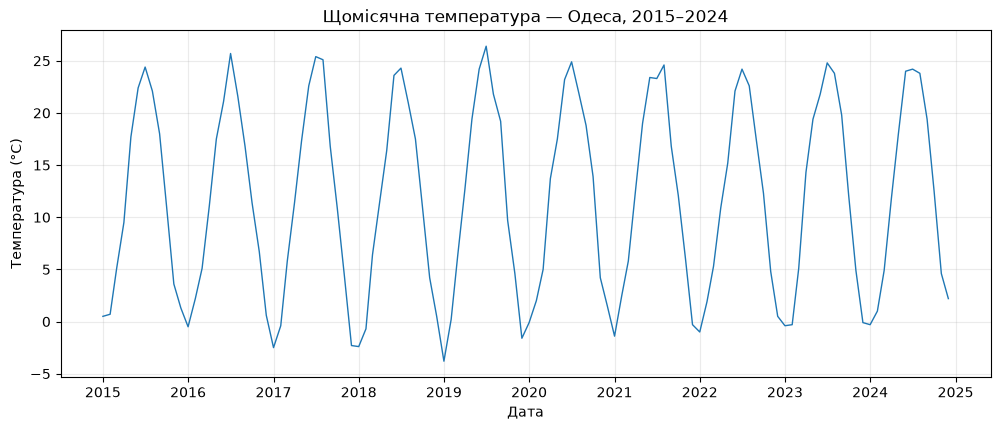

In [2]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(climate_ts.index, climate_ts.values, linewidth=1)
ax.set_xlabel("Дата")
ax.set_ylabel("Температура (°C)")
ax.set_title(f"Щомісячна температура — {city}, 2015–2024")
ax.grid(alpha=0.25)
plt.show()

## Завдання 2. Ковзні середні та лаг

Порівняємо центровані вікна 3 і 12 місяців, а також trailing-вікно 12 місяців (`center=False`). Вікно 12 охоплює повний сезонний період і найкраще прибирає річну хвилю. Центроване середнє розташовує вікно симетрично біля дати; trailing-середнє використовує поточний і попередні місяці, тому реагує із запізненням на зміну рівня.

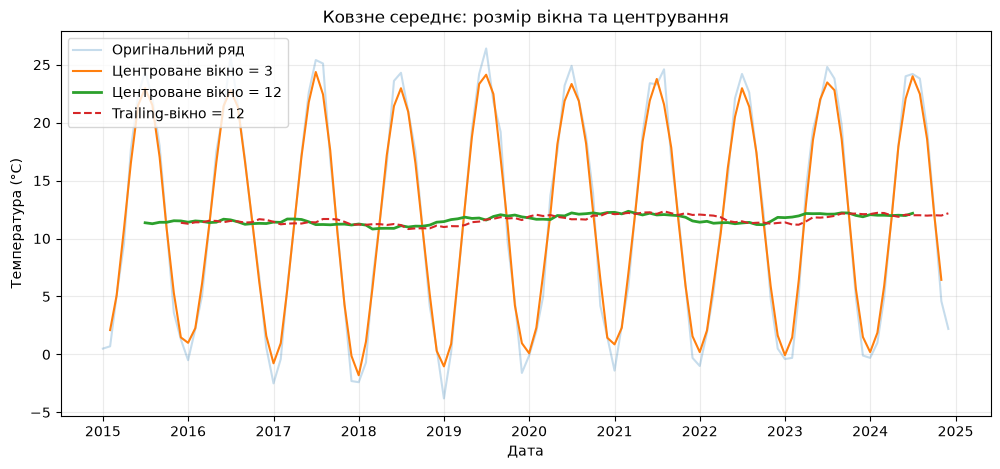

Останні значення центрованого MA(12): {Timestamp('2024-05-01 00:00:00'): 12.008, Timestamp('2024-06-01 00:00:00'): 11.983, Timestamp('2024-07-01 00:00:00'): 12.175}
Останні значення trailing MA(12): {Timestamp('2024-10-01 00:00:00'): 12.008, Timestamp('2024-11-01 00:00:00'): 11.983, Timestamp('2024-12-01 00:00:00'): 12.175}


In [3]:
ma3_centered = climate_ts.rolling(window=3, center=True).mean()
ma12_centered = climate_ts.rolling(window=12, center=True).mean()
ma12_trailing = climate_ts.rolling(window=12).mean()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(climate_ts.index, climate_ts.values, alpha=0.25, label="Оригінальний ряд")
ax.plot(ma3_centered.index, ma3_centered.values, label="Центроване вікно = 3")
ax.plot(ma12_centered.index, ma12_centered.values, linewidth=2, label="Центроване вікно = 12")
ax.plot(ma12_trailing.index, ma12_trailing.values, linestyle="--", label="Trailing-вікно = 12")
ax.set_xlabel("Дата")
ax.set_ylabel("Температура (°C)")
ax.set_title("Ковзне середнє: розмір вікна та центрування")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

print("Останні значення центрованого MA(12):", ma12_centered.dropna().tail(3).round(3).to_dict())
print("Останні значення trailing MA(12):", ma12_trailing.dropna().tail(3).round(3).to_dict())

**Інтерпретація.** Вікно 3 місяці зменшує високочастотний шум, але залишає помітну частину річної сезонності. Центроване вікно 12 місяців охоплює повний цикл і значно краще усереднює сезонну хвилю, залишаючи повільну зміну рівня. Центроване MA(12) доступне лише для дат, де є і попередні, і наступні місяці; trailing MA(12) з'являється раніше й має крайове запізнення, бо усереднює переважно минулі нижчі/вищі значення. Порівняйте обидві лінії на графіку: відмінність найбільш помітна біля початку/кінця та там, де рівень змінюється; центрування не зсуває усереднення вперед, а trailing-вікно відображає історичне середнє на поточній даті.

## Завдання 3. Адитивна декомпозиція

`seasonal_decompose` з періодом 12 оцінює окремо повільний тренд, повторюваний ефект календарного місяця та залишок. Залишок має бути очищений від обох структурних компонентів.

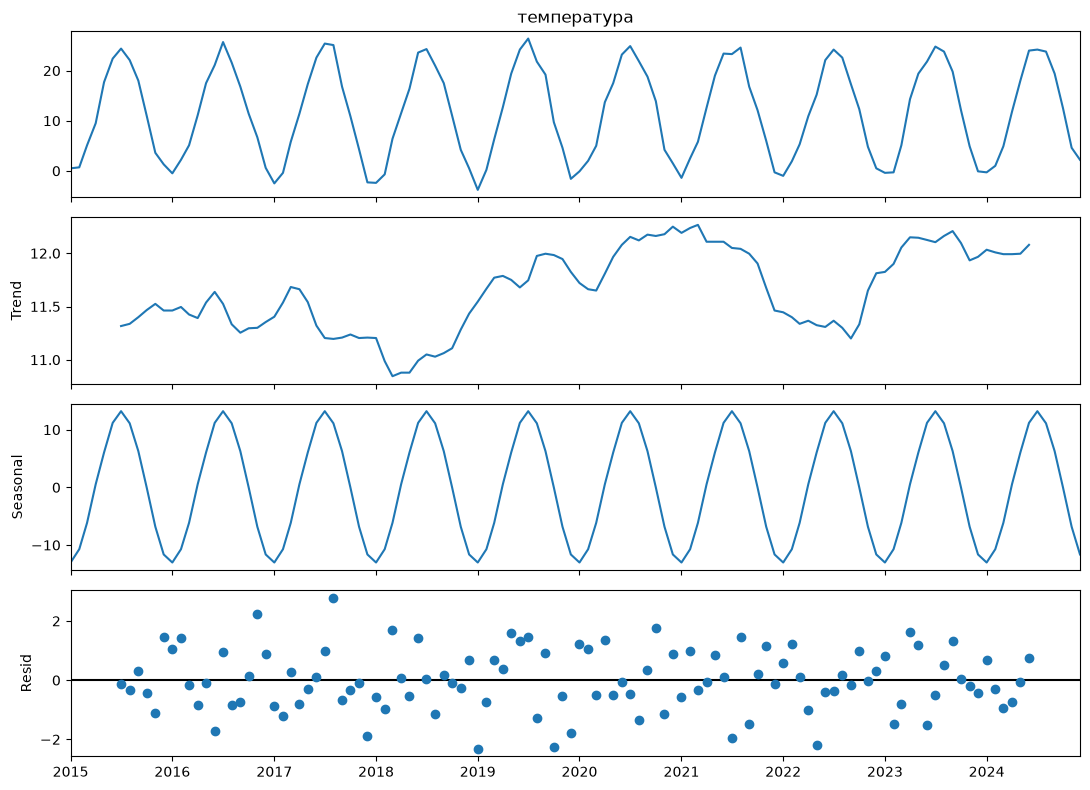

Сезонна компонента за місяцями (°C):


,seasonal
місяць,
1,-13.03
2,-10.72
3,-6.15
4,0.54
5,6.05
6,11.19
7,13.21
8,11.11
9,6.28


Тренд: мінімум 10.846°C, максимум 12.267°C
Стандартне відхилення залишку: 1.035°C
Стандартне відхилення згенерованого шуму: 1.126°C


In [4]:
decomposition = seasonal_decompose(climate_ts, model="additive", period=12)
fig = decomposition.plot()
fig.set_size_inches(11, 8)
plt.tight_layout()
plt.show()

seasonal_by_month = decomposition.seasonal.groupby(decomposition.seasonal.index.month).mean()
print("Сезонна компонента за місяцями (°C):")
display(seasonal_by_month.rename_axis("місяць").to_frame("seasonal").round(2))
print(f"Тренд: мінімум {decomposition.trend.min():.3f}°C, максимум {decomposition.trend.max():.3f}°C")
print(f"Стандартне відхилення залишку: {decomposition.resid.dropna().std():.3f}°C")
print(f"Стандартне відхилення згенерованого шуму: {np.std(noise, ddof=1):.3f}°C")

**Інтерпретація компонент для Одеси.** Оцінений тренд змінюється приблизно від **10.85°C** до **12.27°C** і має загальний плавний підйом — того самого напрямку, що задані 0.05°C/рік, хоча розкид шуму робить його нерівним. Середня сезонна компонента найвища в **липні** (близько +13.21°C відносно рівня), найнижча в **січні** (близько −13.03°C), що узгоджується з косинусним профілем і амплітудою 13°C. Стандартне відхилення залишку — близько **1.04°C**, порівнянне із заданим `noise_scale=1.1°C` і фактичним стандартним відхиленням згенерованого шуму. Отже, декомпозиція відновила основний сезонний профіль і вилучила більшість повільної зміни.

## Завдання 4. Прогноз на 12 місяців

Підганяємо пряму до ненульових оцінок тренду, використовуючи повний індекс часу `0...119` — не перенумеровуємо непорожній фрагмент із середини ряду. До продовженого тренду додаємо середній сезонний ефект відповідного календарного місяця.

Нахил лінії декомпозованого тренду: 0.0848°C/рік


,прогноз_температури
2025-01-01,-0.95
2025-02-01,1.36
2025-03-01,5.94
2025-04-01,12.64
2025-05-01,18.15
2025-06-01,23.30
2025-07-01,25.33
2025-08-01,23.24
2025-09-01,18.41
2025-10-01,12.12


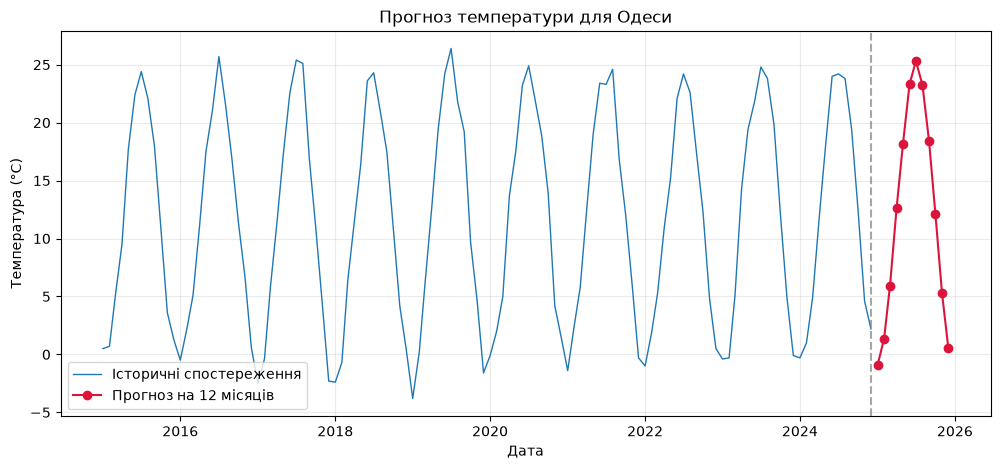

In [5]:
t = np.arange(len(climate_ts))
known = decomposition.trend.notna().to_numpy()
trend_fit = linregress(t[known], decomposition.trend.to_numpy()[known])
n_ahead = 12
t_future = np.arange(len(climate_ts), len(climate_ts) + n_ahead)
trend_forecast = trend_fit.intercept + trend_fit.slope * t_future

seasonal_by_month = decomposition.seasonal.groupby(decomposition.seasonal.index.month).mean()
future_dates = pd.date_range(climate_ts.index[-1] + pd.offsets.MonthBegin(1), periods=n_ahead, freq="MS")
seasonal_forecast = seasonal_by_month.reindex(future_dates.month).to_numpy()
forecast = pd.Series(trend_forecast + seasonal_forecast, index=future_dates, name="прогноз_температури")

print(f"Нахил лінії декомпозованого тренду: {trend_fit.slope * 12:.4f}°C/рік")
display(forecast.round(2).to_frame())

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(climate_ts.index, climate_ts.values, label="Історичні спостереження", linewidth=1)
ax.plot(forecast.index, forecast.values, color="crimson", marker="o", label="Прогноз на 12 місяців")
ax.axvline(climate_ts.index[-1], color="gray", linestyle="--", alpha=0.7)
ax.set_xlabel("Дата")
ax.set_ylabel("Температура (°C)")
ax.set_title("Прогноз температури для Одеси")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

**Застереження щодо прогнозу.** Це механічне продовження прямої тренду з повторенням оціненого сезонного профілю. Воно припускає, що швидкість потепління та сезонний цикл залишаються сталими. Реальні зміни кліматичних режимів, аномальні роки, міські зміни (забудова/озеленення), викиди або зміни вимірювальної станції можуть порушити це припущення. Тому точки на наступний рік — орієнтовний прогноз на короткий горизонт, а не точна гарантія; невизначеність зазвичай зростає зі збільшенням горизонту.

## Завдання 5. Чи підтверджений тренд статистично?

Перевіряємо нахил у ряді без сезонної складової, а не у згладженому тренді. Сусідні точки згладженого тренду залежать через перекривання вікон, тому тест на них міг би штучно занижувати p-value. Нижче також порівнюємо нахил за всі 10 років із оцінкою на останніх трьох роках.

In [6]:
deseason = climate_ts - decomposition.seasonal
t_years = np.arange(len(climate_ts)) / 12
trend_test = linregress(t_years, deseason.to_numpy())
alpha = 0.05
ci_low = trend_test.slope - 1.96 * trend_test.stderr
ci_high = trend_test.slope + 1.96 * trend_test.stderr

print(f"Нахил за 10 роками = {trend_test.slope:.4f}°C/рік")
print(f"Стандартна похибка = {trend_test.stderr:.4f}°C/рік")
print(f"p-value = {trend_test.pvalue:.6f}")
print(f"Наближений 95% ДІ = [{ci_low:.4f}, {ci_high:.4f}]°C/рік")
print("Відхиляємо H₀: нахил дорівнює нулю." if trend_test.pvalue < alpha else "Не відхиляємо H₀: нахил дорівнює нулю.")

short_n = 36
short_fit = linregress(t_years[-short_n:] - t_years[-short_n], deseason.to_numpy()[-short_n:])
short_ci = (short_fit.slope - 1.96 * short_fit.stderr, short_fit.slope + 1.96 * short_fit.stderr)
print(f"Останні 3 роки: slope={short_fit.slope:.4f}°C/рік, stderr={short_fit.stderr:.4f}, p={short_fit.pvalue:.6f}, 95% ДІ=[{short_ci[0]:.4f}, {short_ci[1]:.4f}]")

Нахил за 10 роками = 0.0904°C/рік
Стандартна похибка = 0.0346°C/рік
p-value = 0.010157
Наближений 95% ДІ = [0.0226, 0.1582]°C/рік
Відхиляємо H₀: нахил дорівнює нулю.
Останні 3 роки: slope=0.4351°C/рік, stderr=0.1882, p=0.026961, 95% ДІ=[0.0662, 0.8039]


**Гіпотези та висновок.** Нульова гіпотеза `H₀`: істинний нахил температурного тренду дорівнює нулю — реального потепління немає, а видима зміна пояснюється шумом. Для заданого seed оцінка нахилу ряду без сезонності приблизно **0.090°C/рік**, `p≈0.010`, а наближений 95% довірчий інтервал — **[0.023; 0.158]°C/рік**. Оскільки p-value < 0.05 і інтервал не містить нуля, для цих синтетичних 10 років є підстави відхилити H₀ та вважати нахил статистично підтвердженим. Оцінка більша за закладені 0.05°C/рік — випадкова мінливість і конкретна послідовність шуму впливають на вибірковий нахил.

На останніх трьох роках оцінка нахилу стає приблизно **0.435°C/рік**, набагато більшою за десятирічну, а стандартна похибка зростає приблизно до **0.188°C/рік**; короткий відрізок сильніше реагує на випадкову послідовність шуму, і інтервал оцінки ширший. У цьому конкретному короткому фрагменті p-value також нижче 0.05, але це не робить таку нестійку оцінку надійнішою за оцінку з повного ряду: значення нахилу помітно змінюється при зміні вікна. Висновок спирається на p-value та інтервал, а не просто на те, що нахил додатний.

## Контрольні питання

1. **Чому часовий ряд не аналізують як звичайну незалежну вибірку?** Послідовні місяці пов'язані сезонністю й трендом: значення не є взаємозамінними незалежними спостереженнями, а порядок і часовий інтервал несуть інформацію. Ігнорування залежності може спотворити стандартні похибки та висновки.
2. **Чому крайні розміри вікна — проблема?** Надто мале вікно залишає сезонний цикл і шум; надто велике може стерти локальні зміни й повільніші компоненти. Для місячної річної сезонності вікно 12 місяців охоплює повний цикл і краще усуває сезонний ефект.
3. **Trailing і центроване середнє.** `center=False` позначає середнє попередніх 12 місяців поточним часом і тому запізнюється за зміною рівня. `center=True` симетрично використовує місяці до і після дати, тому краще вирівнює тренд, але потребує майбутніх спостережень відносно дати — у реальному часі вони ще недоступні.
4. **Чому важливий p-value нахилу?** Додатний оцінений нахил може виникнути випадково через шум на скінченному відрізку. p-value перевіряє, наскільки такі дані сумісні з нульовим нахилом, а довірчий інтервал показує точність оцінки; без цього одного знаку slope недостатньо для твердження про підтверджений тренд.

## Підсумок

Для Одеси побудовано 120-місячний ряд 2015–2024 років, порівняно ковзні середні, виконано адитивну декомпозицію, побудовано сезонно скоригований прогноз на 12 місяців і статистично перевірено нахил тренду на повному та коротшому часових вікнах.